# 1. LoG filter

In [1]:
%%writefile common318.py

import numpy as np
import matplotlib.pyplot as plt


def make_gaussian_mask2d(size, sigma):
    r = size // 2
    x = np.arange(-r, r + 1)
    y = np.arange(-r, r + 1)
    X, Y = np.meshgrid(x, y)

    gmask = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
    gmask = gmask / np.sum(gmask)

    return gmask


def imgray(images):
    n = len(images)

    plt.figure(figsize=(5*n, 5))

    for i, img in enumerate(images):
        plt.subplot(1, n, i+1)
        plt.imshow(img, cmap='gray', vmin=0, vmax=255)
        plt.axis('off')

    plt.tight_layout()
    plt.show()

Overwriting common318.py


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.ndimage as ndi
import skimage.transform as tr
import common318 as cm

## a) Load the image file ‘brain_whitenoise.jpg’. 

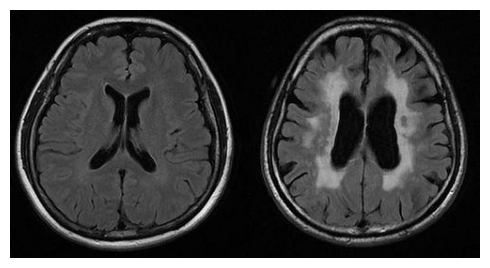

In [3]:
# 1-a) Load the image file 'brain_whitenoise.jpg'

brain = plt.imread('./week6_image/brain_whitenoise.jpg')

cm.imgray([brain])

## b) Apply a Laplacian filter with a kernel size of 5. 

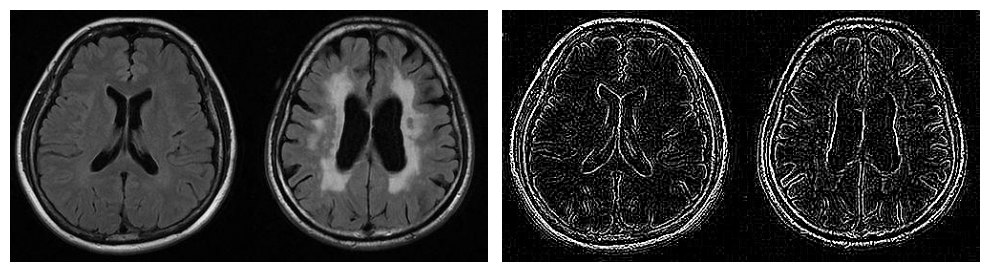

In [4]:
# 1-b) Apply a Laplacian filter with a kernel size of 5

lmask = np.array([
    [ 0,  0, -1,  0,  0],
    [ 0, -1, -2, -1,  0],
    [-1, -2, 16, -2, -1],
    [ 0, -1, -2, -1,  0],
    [ 0,  0, -1,  0,  0]
])

# Convert to float to preserve negative Laplacian responses
brain_f = brain.astype(float)

limg = ndi.convolve(brain_f, lmask)

cm.imgray([brain, limg])

## c) Experiment with the Laplacian of Gaussian (LoG) filter by varying the parameters (kernel size and sigma), then select the combination that produces the best result. 

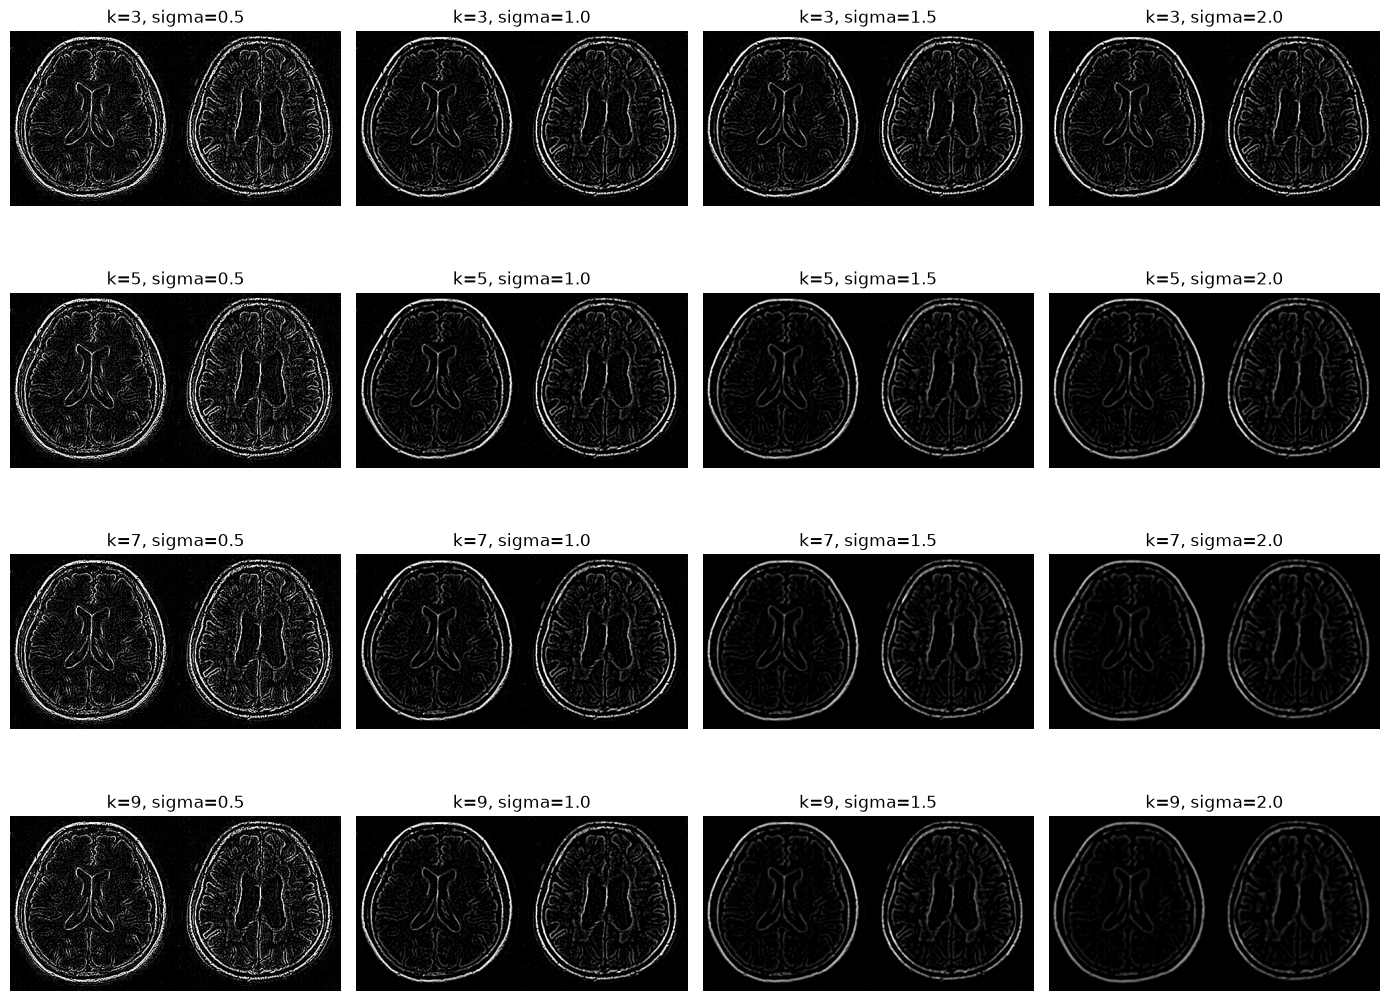

In [5]:
# 1-c) Experiment with the LoG filter
#      by varying kernel size and sigma

sizes = [3, 5, 7, 9]
sigmas = [0.5, 1.0, 1.5, 2.0]

log_results = {}

fig, axes = plt.subplots(
    len(sizes), len(sigmas),
    figsize=(14, 11)
)

for i, size in enumerate(sizes):
    for j, sigma in enumerate(sigmas):

        # Gaussian smoothing
        gmask = cm.make_gaussian_mask2d(size, sigma)
        gimg = ndi.convolve(brain_f, gmask)

        # Laplacian filtering
        logimg = ndi.convolve(gimg, lmask)

        # Save result
        log_results[(size, sigma)] = logimg

        # Display
        axes[i, j].imshow(
            logimg,
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[i, j].set_title(
            f'k={size}, sigma={sigma}'
        )
        axes[i, j].axis('off')

plt.tight_layout()
plt.show()

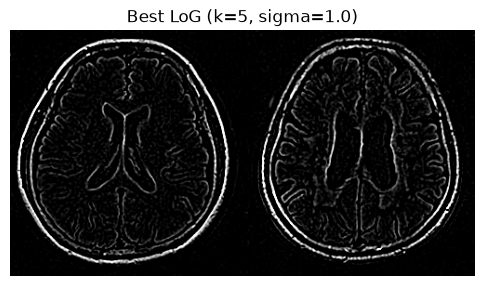

Best LoG parameters: Kernel Size = 5, Sigma = 1.0


In [6]:
# Select and display the best LoG result

best_size = 5
best_sigma = 1.0

best_logimg = log_results[(best_size, best_sigma)]

plt.figure(figsize=(6, 5))
plt.imshow(best_logimg, cmap='gray', vmin=0, vmax=255)
plt.title(f'Best LoG (k={best_size}, sigma={best_sigma})')
plt.axis('off')
plt.show()

print(f'Best LoG parameters: Kernel Size = {best_size}, Sigma = {best_sigma}')

Kernel size 5 and sigma 1.0 were selected because they provided the best balance between noise suppression and edge preservation.

## d) Display the original image, the Laplacian-filtered image, and the best LoG-filtered image together in the same window for comparison. 

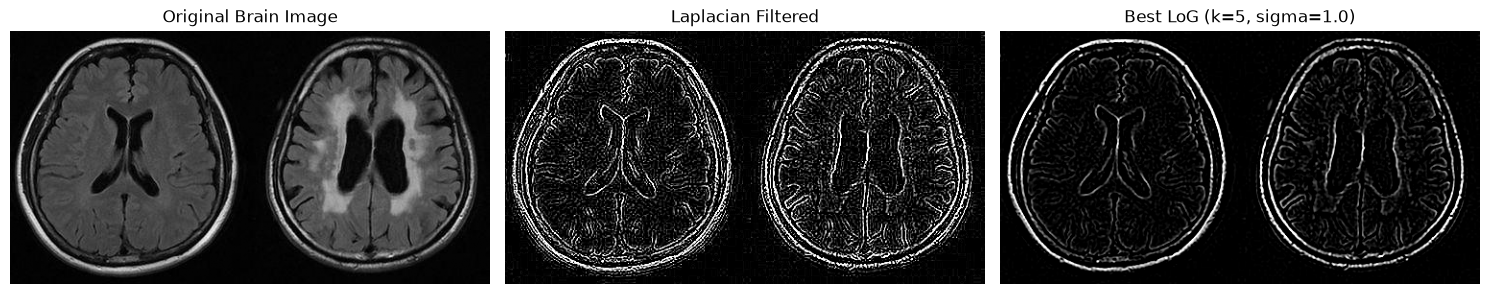

In [7]:
# 1-d) Display the original, Laplacian-filtered,
#      and best LoG-filtered images together

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(brain, cmap='gray', vmin=0, vmax=255)
plt.title('Original Brain Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(limg, cmap='gray', vmin=0, vmax=255)
plt.title('Laplacian Filtered')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(best_logimg, cmap='gray', vmin=0, vmax=255)
plt.title(f'Best LoG (k={best_size}, sigma={best_sigma})')
plt.axis('off')

plt.tight_layout()
plt.show()

# 2. Median Filter 

## a) Load the image file ‘sadimg.bmp’. 

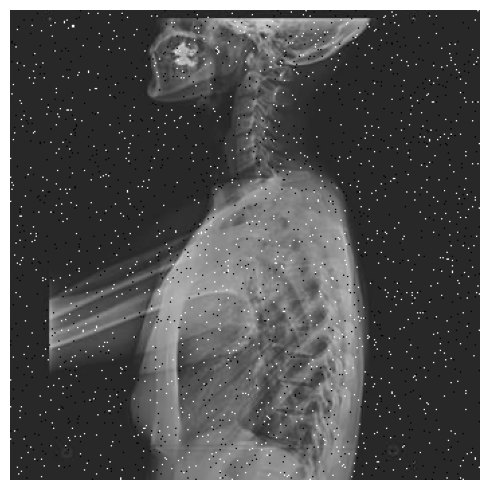

In [8]:
# 2-a) Load the image file 'sadimg.bmp'

sad = plt.imread('./week6_image/sadimg.bmp')

cm.imgray([sad])

## b) Implement a custom median filtering function, median_filt(), and apply it to the image from step a). 
 Input: source image, filter size 
 Output: median-filtered image 
 Do not use any built-in Python library methods for median filtering such as 
skimage.ndimage.median_filter() or rank_filter(). 

In [9]:
# 2-b) Custom median filtering function

def median_filt(src, filter_size):
    
    # filter size must be odd
    if filter_size % 2 == 0:
        raise ValueError("filter_size must be an odd number.")
    
    pad = filter_size // 2
    
    # pad image boundary
    padded = np.pad(src, pad, mode='edge')
    
    # output image
    dst = np.zeros_like(src)
    
    rows, cols = src.shape
    
    for i in range(rows):
        for j in range(cols):
            
            # get local neighborhood
            window = padded[
                i:i + filter_size,
                j:j + filter_size
            ]
            
            # sort pixel values
            values = np.sort(window.flatten())
            
            # choose the middle value
            median_value = values[len(values) // 2]
            
            dst[i, j] = median_value
    
    return dst


# Apply 3x3 custom median filter
sad_median = median_filt(sad, 3)

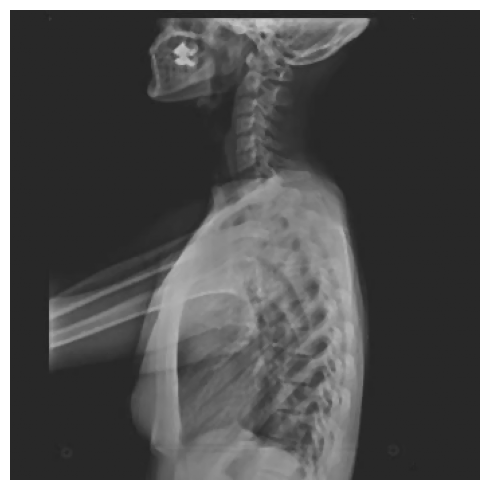

In [10]:
cm.imgray([sad_median])

## c) Display both the original and the median-filtered image. 

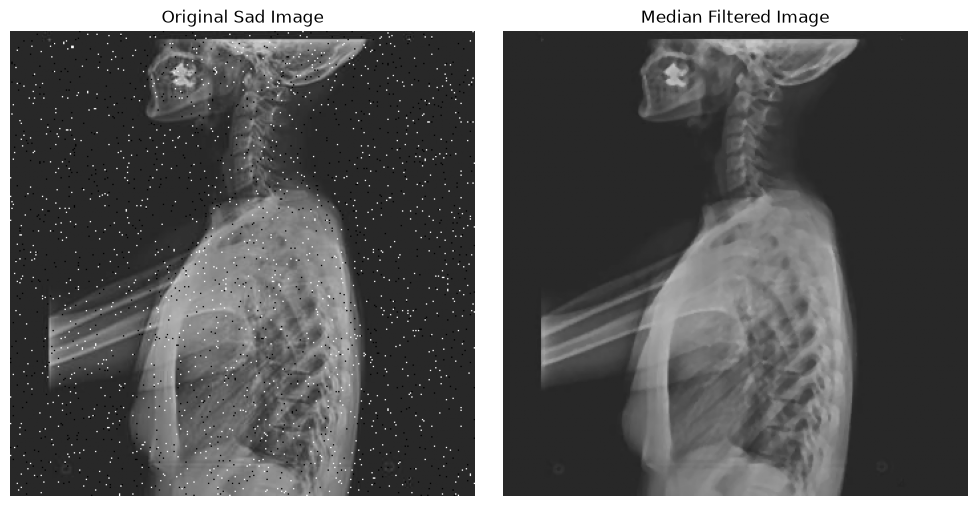

In [11]:
# 2-c) Display the original and the median-filtered image

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sad, cmap='gray', vmin=0, vmax=255)
plt.title('Original Sad Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(sad_median, cmap='gray', vmin=0, vmax=255)
plt.title('Median Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()

# 3. Interpolation 

## a) Load the image file ‘body.jpg’. 

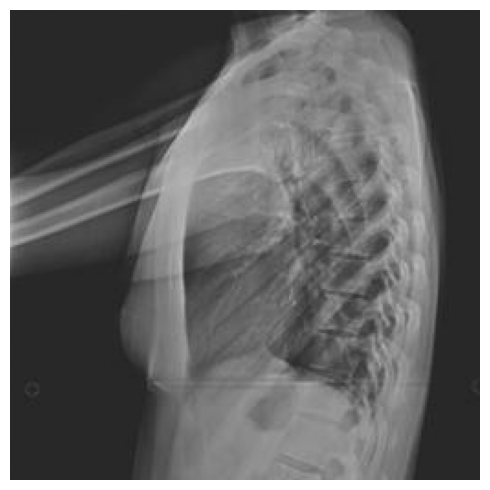

In [12]:
# 3-a) Load the image file 'body.jpg'

body = plt.imread('./week6_image/body.jpg')

cm.imgray([body])

## b) Resize the image from step a) to 64×64 pixels using bilinear interpolation. 

Original size: (256, 256)
Resized size: (64, 64)


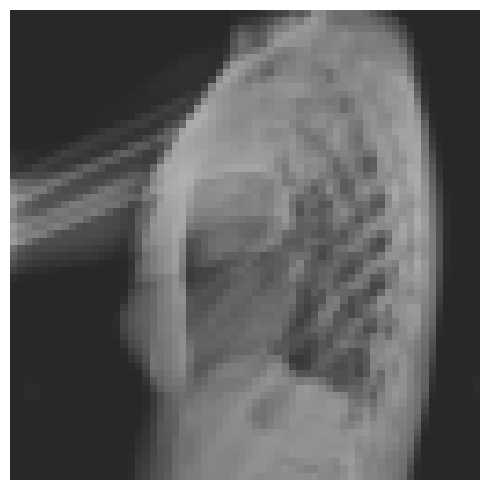

In [13]:
# 3-b) Resize the image to 64x64 using bilinear interpolation

body_64 = tr.rescale(body, 0.25, order=1) * 255

print('Original size:', body.shape)
print('Resized size:', body_64.shape)

cm.imgray([body_64])

## c) Resize the 64×64 image back to the original dimensions using three methods: nearest neighbor, bilinear, and bicubic interpolation. 

In [14]:
# 3-c) Resize the 64x64 image back to the original size
#      using nearest neighbor, bilinear, and bicubic interpolation

# Nearest neighbor
body_nearest = tr.rescale(
    body_64, 4,
    order=0,
    preserve_range=True
)

# Bilinear
body_bilinear = tr.rescale(
    body_64, 4,
    order=1,
    preserve_range=True
)

# Bicubic
body_bicubic = tr.rescale(
    body_64, 4,
    order=3,
    preserve_range=True
)

print('Nearest neighbor:', body_nearest.shape)
print('Bilinear:', body_bilinear.shape)
print('Bicubic:', body_bicubic.shape)

Nearest neighbor: (256, 256)
Bilinear: (256, 256)
Bicubic: (256, 256)


## d) Display the original image and the three resized versions in the same figure window. 

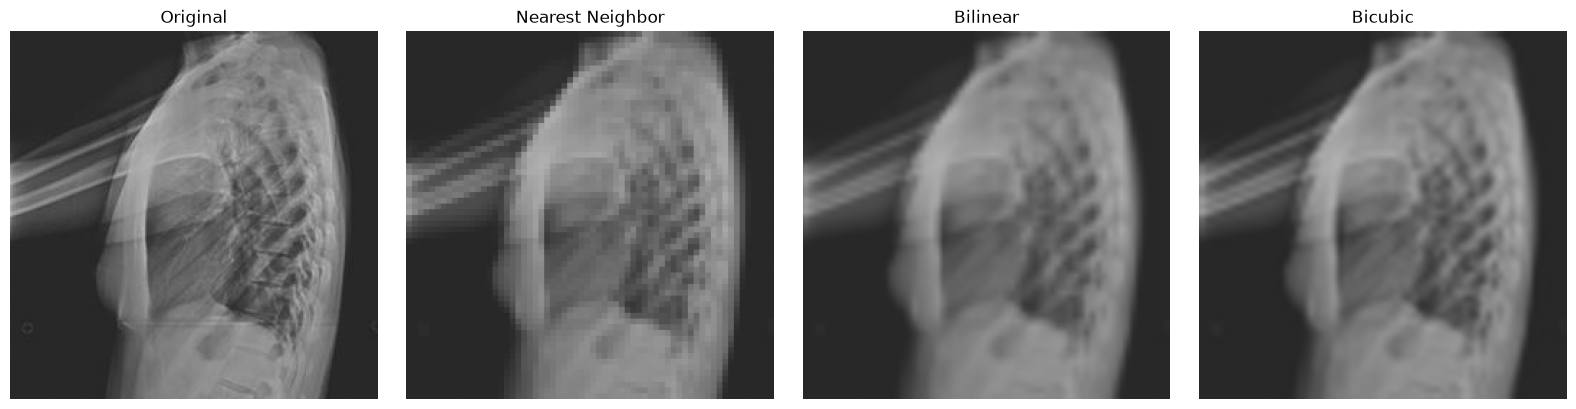

In [15]:
# 3-d) Display the original image and the three resized images together

images = [
    body,
    body_nearest,
    body_bilinear,
    body_bicubic
]

titles = [
    'Original',
    'Nearest Neighbor',
    'Bilinear',
    'Bicubic'
]

plt.figure(figsize=(16, 4))

for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

## e) Display a separate image showing the pixel-wise differences between the bilinear- and bicubic-resized images. 

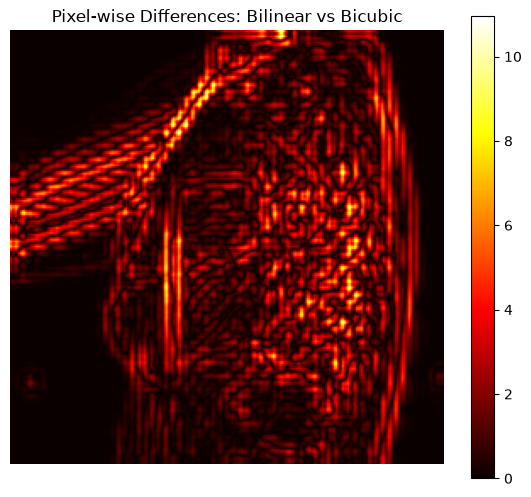

In [16]:
# 3-e) Display the pixel-wise difference
#      between bilinear and bicubic interpolation

diff_image = np.abs(body_bilinear - body_bicubic)

plt.figure(figsize=(7, 6))

im = plt.imshow(diff_image, cmap='hot')
plt.title('Pixel-wise Differences: Bilinear vs Bicubic')
plt.axis('off')

plt.colorbar(im)

plt.show()

# 4. Rotation

## a) Load the image file ‘body.jpg’. 

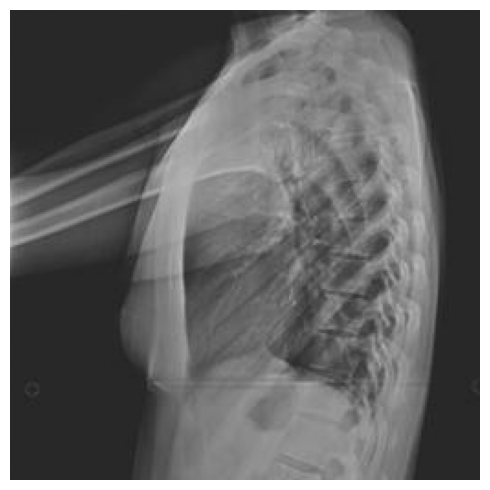

In [17]:
# 4-a) Load the image file 'body.jpg'

body = plt.imread('./week6_image/body.jpg')

cm.imgray([body])

## b) Rotate the image by 30 degrees using both nearest neighbor and bicubic interpolation methods. 

In [18]:
# 4-b) Rotate the image by 30 degrees
#      using nearest neighbor and bicubic interpolation

# Nearest neighbor interpolation
body_rot_nearest = tr.rotate(
    body,
    30,
    order=0,
    preserve_range=True
)

# Bicubic interpolation
body_rot_bicubic = tr.rotate(
    body,
    30,
    order=3,
    preserve_range=True
)

print('Nearest neighbor:', body_rot_nearest.shape)
print('Bicubic:', body_rot_bicubic.shape)

Nearest neighbor: (256, 256)
Bicubic: (256, 256)


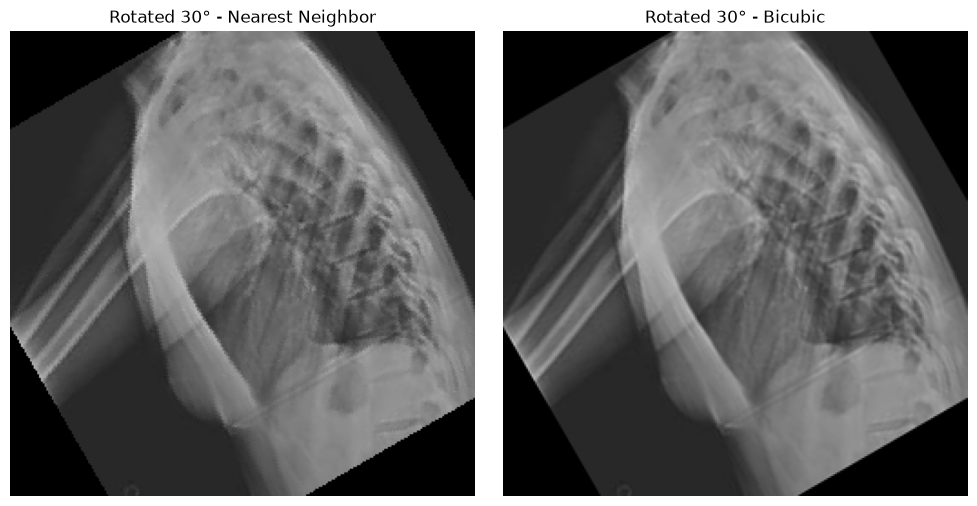

In [19]:
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(body_rot_nearest, cmap='gray', vmin=0, vmax=255)
plt.title('Rotated 30° - Nearest Neighbor')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(body_rot_bicubic, cmap='gray', vmin=0, vmax=255)
plt.title('Rotated 30° - Bicubic')
plt.axis('off')

plt.tight_layout()
plt.show()

## c) Display the original image, the rotated images, and a difference image highlighting the pixel-wise changes between the two rotated versions. Convert the difference image to black and white, where all zero values appear black and all other pixel values appear white. 

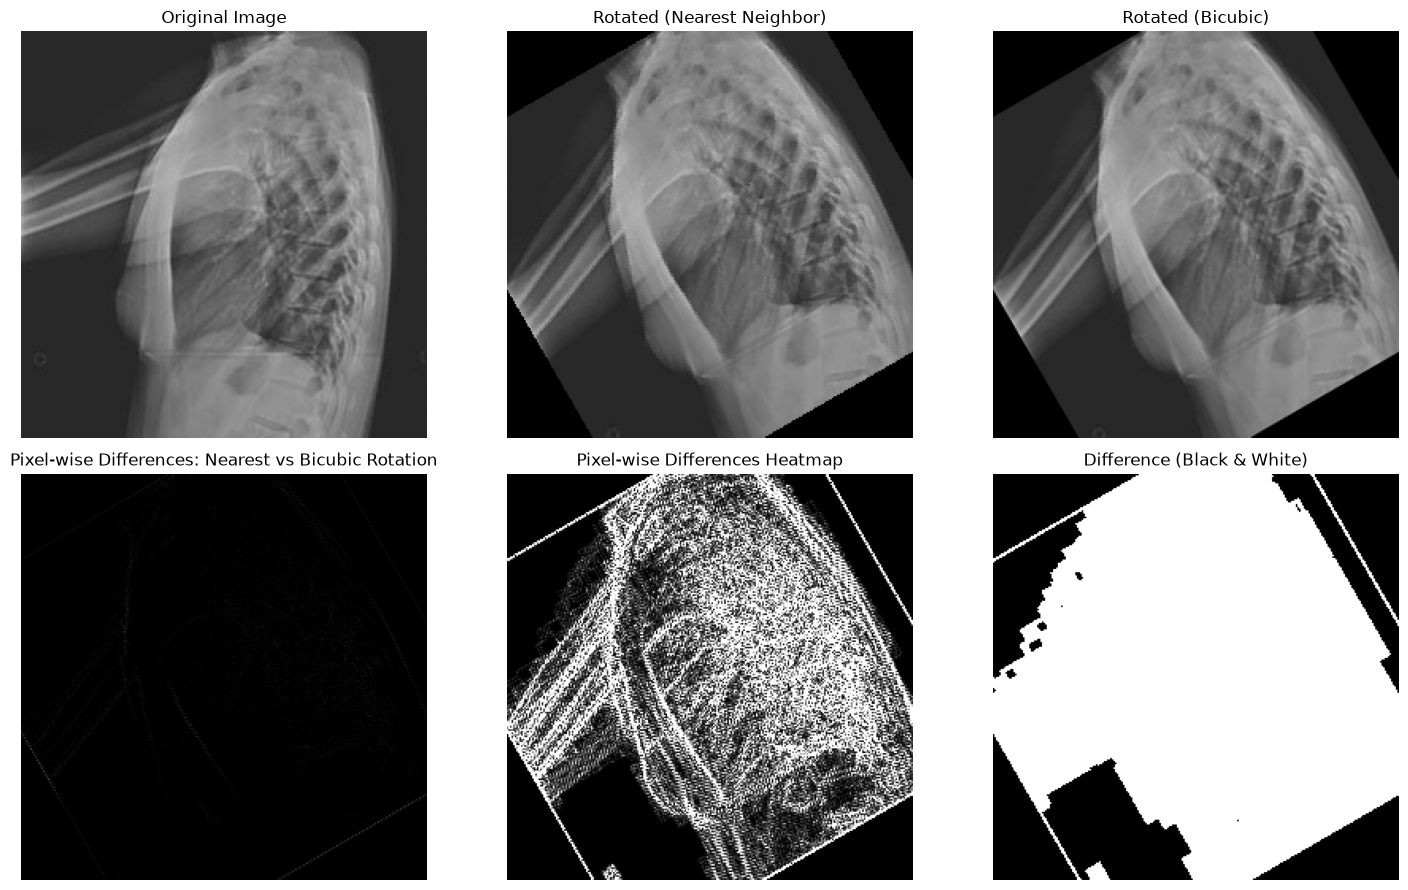

In [20]:
# 4-c) Display the original image, rotated images,
#      and pixel-wise difference images

# Pixel-wise absolute difference
diff_rot = np.abs(body_rot_nearest - body_rot_bicubic)

# Black & white difference
# zero -> black, non-zero -> white
diff_bw = np.where(diff_rot == 0, 0, 255)

# Contrast setting for the heatmap
nonzero_diff = diff_rot[diff_rot > 0]
heat_vmax = np.percentile(nonzero_diff, 75)


plt.figure(figsize=(15, 9))


# -------------------------
# Top row
# -------------------------

# Original image
plt.subplot(2, 3, 1)
plt.imshow(body, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.axis('off')

# Rotated image - nearest neighbor
plt.subplot(2, 3, 2)
plt.imshow(body_rot_nearest, cmap='gray', vmin=0, vmax=255)
plt.title('Rotated (Nearest Neighbor)')
plt.axis('off')

# Rotated image - bicubic
plt.subplot(2, 3, 3)
plt.imshow(body_rot_bicubic, cmap='gray', vmin=0, vmax=255)
plt.title('Rotated (Bicubic)')
plt.axis('off')


# -------------------------
# Bottom row
# -------------------------

# Raw pixel-wise difference
plt.subplot(2, 3, 4)
plt.imshow(diff_rot, cmap='gray', vmin=0, vmax=255)
plt.title('Pixel-wise Differences: Nearest vs Bicubic Rotation')
plt.axis('off')

# Contrast-enhanced difference
plt.subplot(2, 3, 5)
plt.imshow(
    diff_rot,
    cmap='gray',
    vmin=0,
    vmax=heat_vmax
)
plt.title('Pixel-wise Differences Heatmap')
plt.axis('off')

# Black & white difference
plt.subplot(2, 3, 6)
plt.imshow(diff_bw, cmap='gray', vmin=0, vmax=255)
plt.title('Difference (Black & White)')
plt.axis('off')


plt.tight_layout()
plt.show()

# 5. Image geometry 

## a) Load the image file ‘sadimg2.bmp’. 

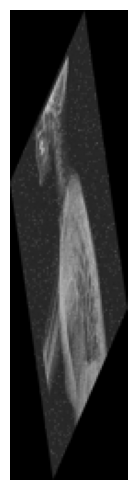

In [21]:
# 5-a) Load the image file 'sadimg2.bmp'

sad2 = plt.imread('./week6_image/sadimg2.bmp')

cm.imgray([sad2])

## b) The image in step a) was generated from the original image 'img.jpg' through the following processes: ① Addition of salt & pepper noise ② Rotation by 30 degrees using bicubic interpolation ③ Size reduction to 256 × 64 

### 5-b) Generation process of sadimg2.bmp

The processed image `sadimg2.bmp` was generated from `img.jpg` by:

1. Adding salt-and-pepper noise
2. Rotating the image by 30° using bicubic interpolation
3. Resizing the image to 256 × 64 pixels

## c) Restore the processed image (‘sadimg2.bmp’) to resemble the original ‘img.jpg’ as closely as possible. 

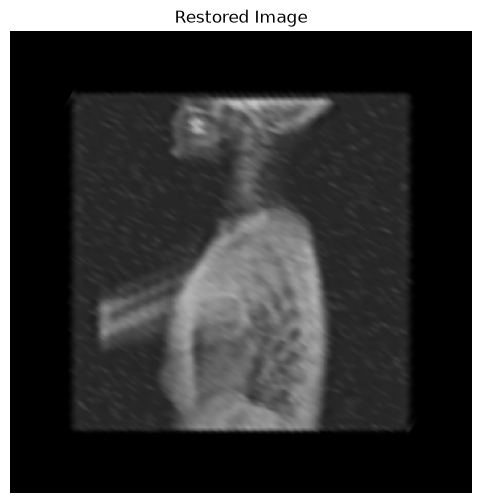

In [22]:
# 5-c) Restore sadimg2.bmp to resemble img.jpg as closely as possible

# Load original image
img = plt.imread('./week6_image/img.jpg')

# 1. Restore to the original image size using bicubic interpolation
restored_size = tr.resize(
    sad2,
    img.shape,
    order=3,                 # bicubic
    preserve_range=True,
    anti_aliasing=False
)

# 2. Undo the 30-degree rotation
restored_rot = tr.rotate(
    restored_size,
    -30,
    order=3,                 # bicubic
    resize=False,
    preserve_range=True
)

# 3. Remove salt-and-pepper noise
restored = median_filt(restored_rot, 3)

restored = np.clip(restored, 0, 255)

plt.figure(figsize=(6, 6))
plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
plt.title('Restored Image')
plt.axis('off')
plt.show()

## d) Display the original image, the processed image (‘sadimg2.bmp’), and the restored image together in the same figure window. 

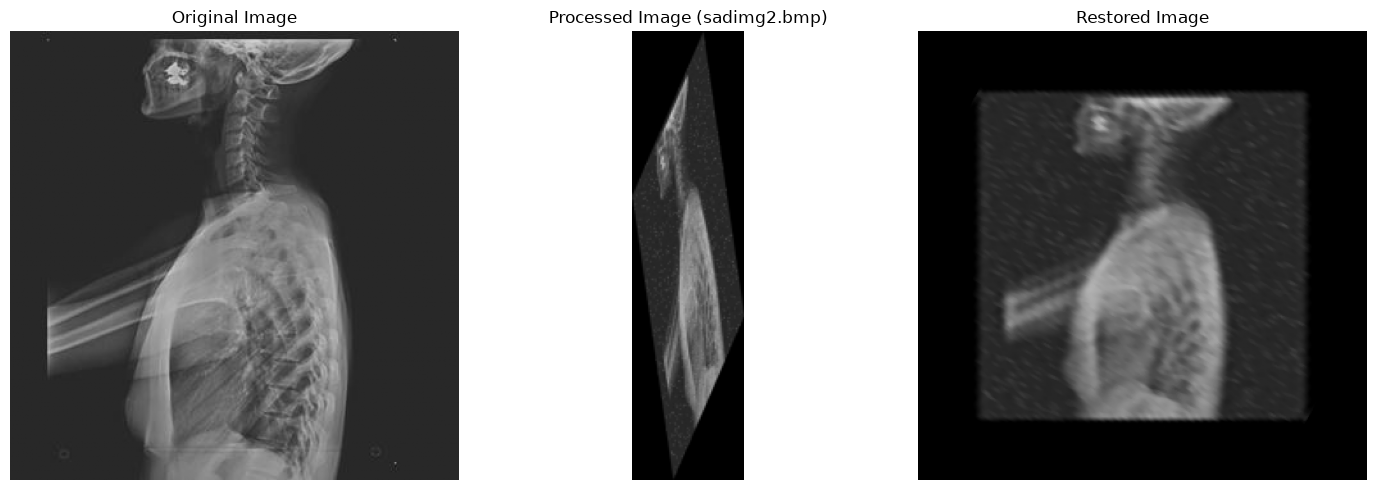

In [23]:
# 5-d) Display original, processed, and restored images together

plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.axis('off')

# Processed image
plt.subplot(1, 3, 2)
plt.imshow(sad2, cmap='gray', vmin=0, vmax=255)
plt.title('Processed Image (sadimg2.bmp)')
plt.axis('off')

# Restored image
plt.subplot(1, 3, 3)
plt.imshow(restored, cmap='gray', vmin=0, vmax=255)
plt.title('Restored Image')
plt.axis('off')

plt.tight_layout()
plt.show()

# 6. Image geometry: Affine transform 

## a) Load the image files ‘img.jpg’ (original) and ‘affined_img.bmp’ (affine-transformed).

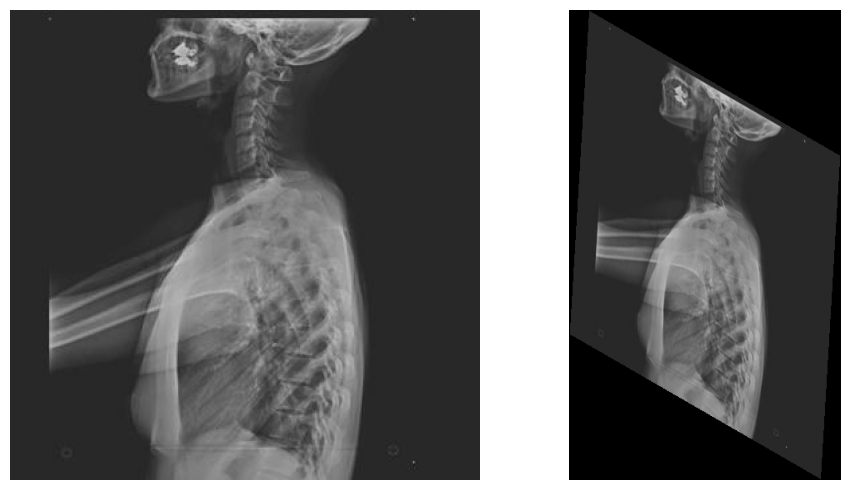

In [24]:
# 6-a) Load the original and affine-transformed images

img = plt.imread('./week6_image/img.jpg')
affined_img = plt.imread('./week6_image/affined_img.bmp')

cm.imgray([img, affined_img])

## b) Apply an appropriate inverse affine transformation to ‘affined_img.bmp’ to reconstruct an image as close as possible to the original ‘img.jpg’. 

C:\Users\user\AppData\Local\Temp\ipykernel_2248\1957123014.py:39: FutureWarning: `estimate` is deprecated since version 0.26 and will be removed in version 2.2. Please use `AffineTransform.from_estimate` class constructor instead.
  tform.estimate(original_corners, affine_corners)


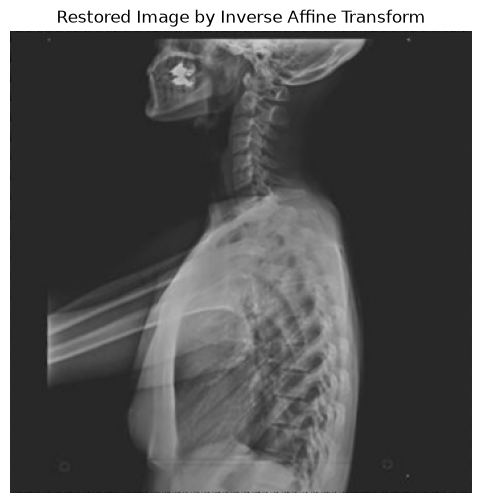

In [25]:
# 6-b) Apply an inverse affine transformation

# Original image size
h, w = img.shape

# Find the non-black region of the affine-transformed image
mask = affined_img > 0

y, x = np.nonzero(mask)
points = np.column_stack((x, y)).astype(float)

# Detect four corners of the transformed parallelogram
sum_xy = points[:, 0] + points[:, 1]
diff_xy = points[:, 0] - points[:, 1]

top_left     = points[np.argmin(sum_xy)]
bottom_right = points[np.argmax(sum_xy)]
top_right    = points[np.argmax(diff_xy)]
bottom_left  = points[np.argmin(diff_xy)]

affine_corners = np.array([
    top_left,
    top_right,
    bottom_right,
    bottom_left
])

# Corresponding corners in the original image
original_corners = np.array([
    [0,     0],
    [w - 1, 0],
    [w - 1, h - 1],
    [0,     h - 1]
], dtype=float)

# Estimate affine transformation:
# original coordinates -> affine-transformed coordinates
tform = tr.AffineTransform()
tform.estimate(original_corners, affine_corners)

# Inverse mapping to reconstruct the original image
restored_affine = tr.warp(
    affined_img,
    inverse_map=tform,
    output_shape=img.shape,
    order=3,                 # bicubic interpolation
    preserve_range=True
)

restored_affine = np.clip(restored_affine, 0, 255)

# Display restored image
plt.figure(figsize=(6, 6))
plt.imshow(restored_affine, cmap='gray', vmin=0, vmax=255)
plt.title('Restored Image by Inverse Affine Transform')
plt.axis('off')
plt.show()

## c) Display all three images—the original, the affine-transformed, and the restored—in a single figure window for comparison. 

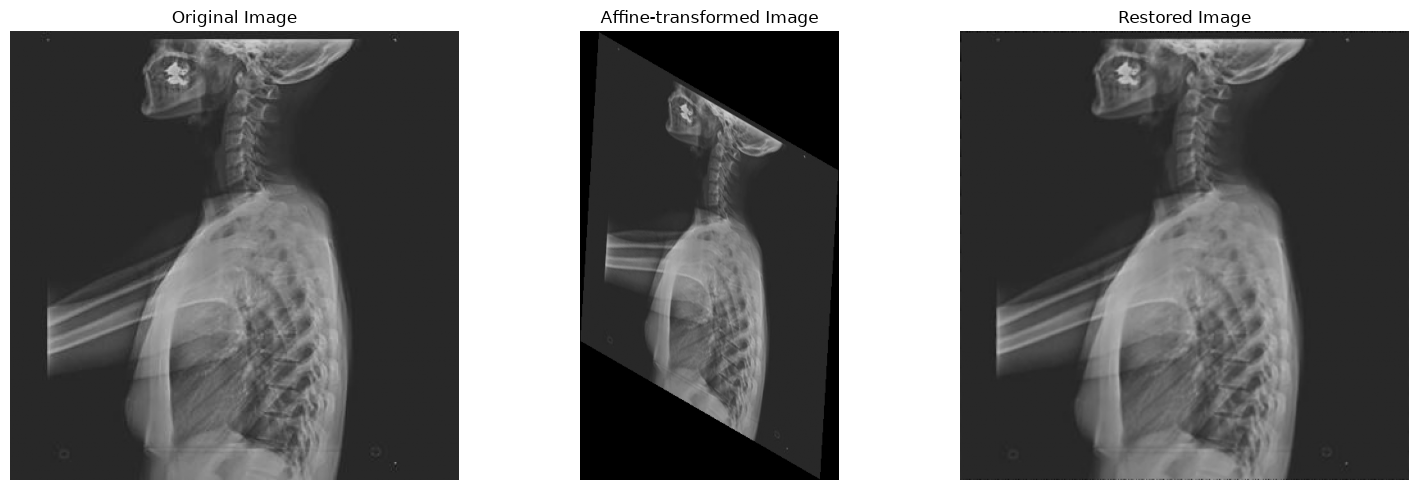

In [26]:
# 6-c) Display the original, affine-transformed,
#      and restored images together

plt.figure(figsize=(15, 5))

# Original image
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title('Original Image')
plt.axis('off')

# Affine-transformed image
plt.subplot(1, 3, 2)
plt.imshow(affined_img, cmap='gray', vmin=0, vmax=255)
plt.title('Affine-transformed Image')
plt.axis('off')

# Restored image
plt.subplot(1, 3, 3)
plt.imshow(restored_affine, cmap='gray', vmin=0, vmax=255)
plt.title('Restored Image')
plt.axis('off')

plt.tight_layout()
plt.show()